# Subseasonal skill of tropical winds

## Purpose

Daily spatial anomaly correlation and RMSE of the tropical (20S-20N) 850- and 200-hPa zonal wind against ERA5 over the first `LEAD_DAYS_MAX` days.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Daily U850, U200. Reference: ERA5 daily U850/U200 (daily means of `OBSERVATION_ROOT/ERA5/1x1/6hourly`; variables without a reference are skipped).

## Method

Anomalies per `ANOM_METHOD`: `harmonics` (default; record mean plus 3 annual harmonics, valid from day 0), `bandpass_20_100` (Lanczos, 201 taps: model leads < 100 days are lost because the run starts at the initial date), or `rm60`. Daily cos-lat weighted ACC and RMSE, `SMOOTH_DAYS` running means, and window-mean ACC with a moving-block bootstrap 95% CI.

## Outputs

`data/hind_atm_eval/wind/wind_skill_<VAR>.nc`, `wind_skill_windows.csv`; figures in `figure/hind_atm_eval/wind/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

EXPERIMENTS = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
VARIABLES = ("U850", "U200")
START, END = "2012-01-01", "2013-12-31"
INIT_DATE = "2012-01-01"
LAT_RANGE = (-20.0, 20.0)
LEAD_DAYS_MAX = 120
ANOM_METHOD = "harmonics"   # "harmonics" | "bandpass_20_100" | "rm60"
SMOOTH_DAYS = 7
LEAD_WINDOWS = ((5, 14), (15, 28), (29, 42))
FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'wind', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/wind
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind


## 4. Read input

Saved skill files are reused when they hold every experiment (unless `FORCE_COMPUTE`); otherwise daily ERA5 and model winds of that variable are opened lazily. A variable without an ERA5 file is skipped.

In [4]:
from configs.hind_experiment_config import check_experiments
from util.hind_model_data import open_model_daily
from util.hind_observation_data import open_reference_daily

check_experiments(EXPERIMENTS)
paths = {var: data_dir / f"wind_skill_{var}.nc" for var in VARIABLES}


def saved(path):
    if FORCE_COMPUTE or not path.exists():
        return False
    with xr.open_dataset(path) as ds:
        return set(EXPERIMENTS) <= set(ds.experiment.values)


inputs = {}
for var in VARIABLES:
    if saved(paths[var]):
        continue
    try:
        ref = open_reference_daily("ERA5_DAILY", var, start=START, end=END, **ROOTS)
    except FileNotFoundError as err:
        print(f"[SKIP] {var}: {err}")
        continue
    inputs[var] = {"ERA5": ref, **{e: open_model_daily(e, var, data_root=INPUT_DATA_ROOT, start=START, end=END)
                                   for e in EXPERIMENTS}}
print(f"[READ] {', '.join(inputs) or 'nothing: every skill file is saved'}")

[READ] nothing: every skill file is saved


## 5. Derive

Daily ACC and RMSE against ERA5 by lead day. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.tropical_wind_skill import WindSkillConfig, daily_skill, domain_subset

cfg = WindSkillConfig(lat_range=LAT_RANGE, lead_days_max=LEAD_DAYS_MAX, anom_method=ANOM_METHOD,
                      smooth_days=SMOOTH_DAYS, lead_windows=LEAD_WINDOWS)
fields = compute_all({(var, s): domain_subset(da, cfg) for var, f in inputs.items() for s, da in f.items()})
derived = {var: {e: daily_skill(fields[var, e], fields[var, "ERA5"], INIT_DATE, cfg) for e in EXPERIMENTS}
           for var in inputs}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files.

In [6]:
for var, sk in derived.items():
    xr.concat([s.expand_dims(experiment=[e]) for e, s in sk.items()], "experiment").to_netcdf(paths[var])
    print(f"[WRITE] {paths[var]}")
skills = {}
for var, path in paths.items():
    if path.exists():
        ds = xr.load_dataset(path)
        skills[var] = {e: ds.sel(experiment=e, drop=True) for e in EXPERIMENTS}

## 7. Scores

Window-mean ACC with its bootstrap CI.

In [7]:
from util.tropical_wind_skill import window_table

table = pd.concat([window_table(s, cfg).assign(variable=var, experiment=e)
                   for var, sk in skills.items() for e, s in sk.items()])
table.to_csv(data_dir / "wind_skill_windows.csv", index=False)
print(f"[WRITE] {data_dir / 'wind_skill_windows.csv'}")
display(table.pivot_table(index=["variable", "experiment"], columns="window", values="ACC").round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/wind/wind_skill_windows.csv


window               05-14  15-28  29-42
variable experiment                     
U200     CTRL        -0.01  -0.06   0.04
         DARTAE       0.27   0.22  -0.08
         DARTBA       0.01   0.08  -0.02
         DARTBL       0.29   0.21   0.08
         DARTOP       0.28   0.20  -0.03
         ERA5BL       0.22  -0.15  -0.03
         ERA5DL       0.16  -0.07  -0.01
         ERA5OP       0.18  -0.16  -0.08
U850     CTRL        -0.02  -0.00  -0.11
         DARTAE       0.25   0.11   0.01
         DARTBA       0.01   0.06  -0.01
         DARTBL       0.26   0.01  -0.00
         DARTOP       0.27   0.10   0.01
         ERA5BL       0.18   0.02  -0.09
         ERA5DL       0.19   0.00  -0.01
         ERA5OP       0.15  -0.03   0.02

## 8. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_U850.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_U200.png


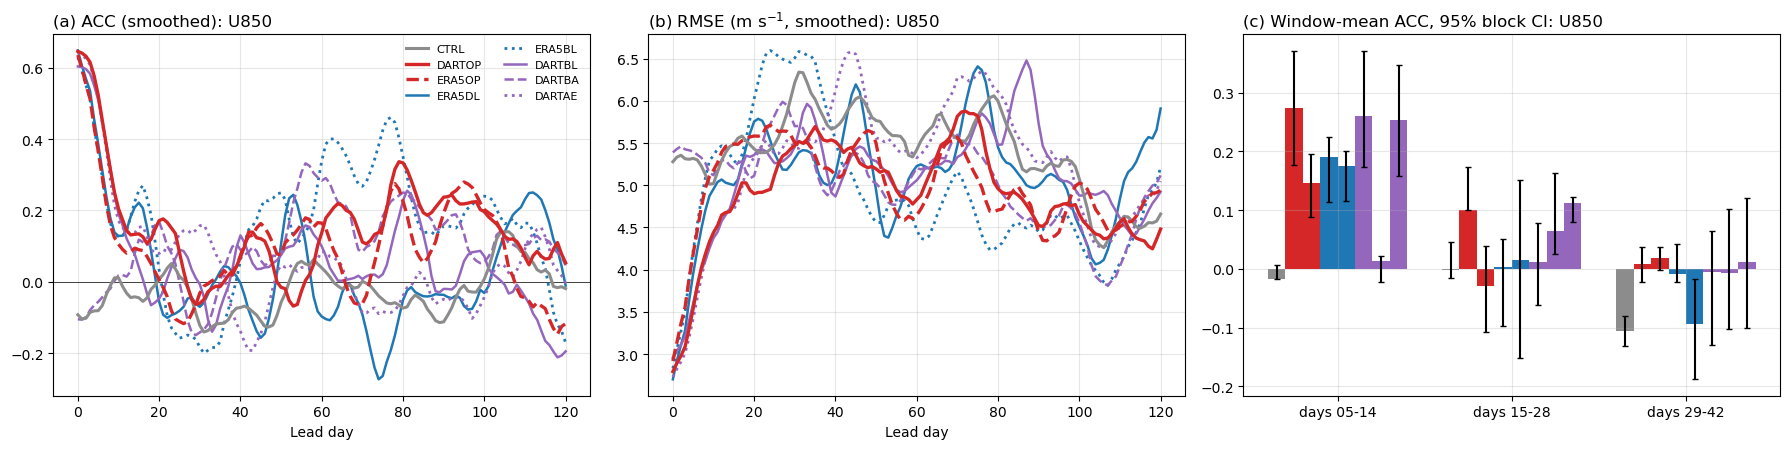

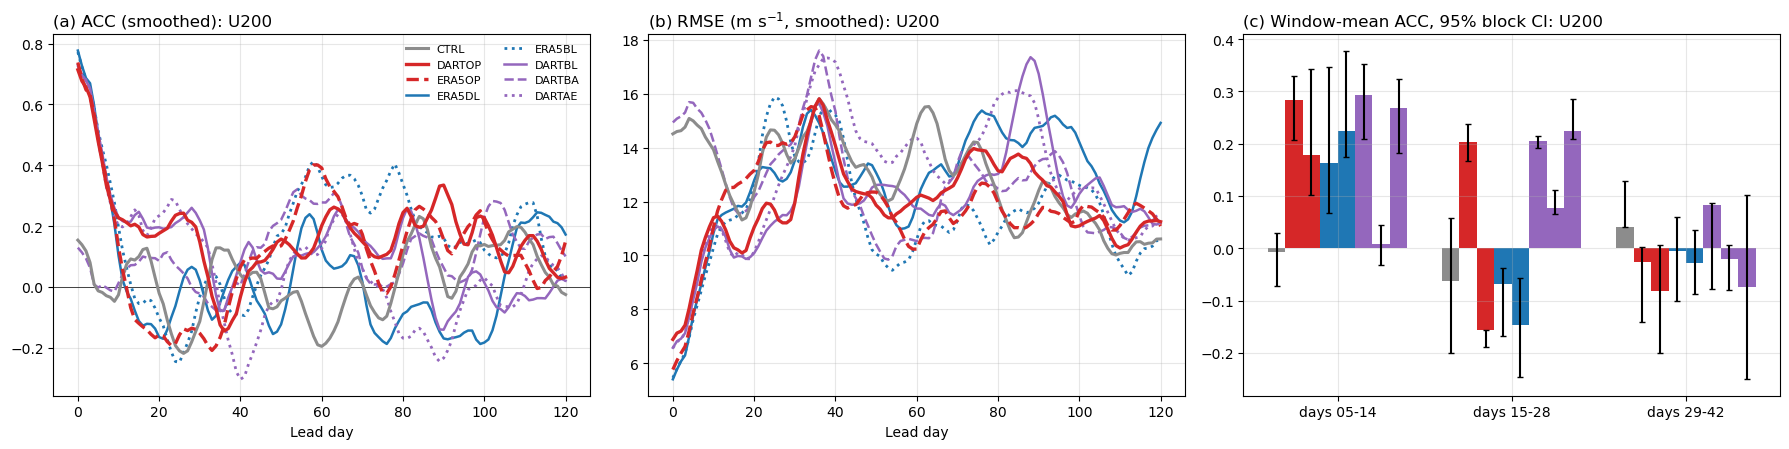

In [8]:
from util.tropical_wind_skill import plot_wind_skill

for var, sk in skills.items():
    save(plot_wind_skill(sk, table[table.variable == var], var), f"wind_skill_{var}.png")